<a href="https://colab.research.google.com/github/OwenLoughery/Project3-Wine_Reviews/blob/main/4401_Project_3_EDA_Stanley.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##Introduction
I will be examining batch 2 which consists of Chardonnay, 	Sparkling, Sangiovese, 	White Blend (generic), 	Aromatic Whites and 	Fortified & Dessert. This first part of the project will be primarily exploratory data analysis (EDA). I will explore these style of wine and report back any interesting findings.

##Pre-Processing

In [40]:
!pip -q install nltk pandas pyarrow tqdm

import pandas as pd
import os
import re
import nltk

from tqdm.auto import tqdm
from IPython.display import display
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

tqdm.pandas()

for pkg in ["punkt_tab", "stopwords", "wordnet"]:
    nltk.download(pkg, quiet=True)

LEMMATIZER = WordNetLemmatizer()

CSV_PATH = "/content/winemag-data-130k-v2.csv"
OUTPUT_PATH = "/content/processed_reviews.parquet"

In [43]:
# Common words shared among wines
WINE_WORDS = {
    "wine", "flavor", "palate",
    "drink", "note", "show"
}

# Words to preserve
KEEP = {
    "red", "white", "apple", "blend", "style",
    "other", "de", "di", "del", "la",
    "black", "orange", "melon", "vital",
    "grain", "diamond", "mission", "du",
    "sparkling", "champagne", "port"
}

# Grape nicknames and masking placeholders
NICKNAMES = {
    "cab", "zin", "chard", "sauv",
    "gewürz", "gewurz", "grüner",
    "gruner", "varietyname"
}


def base_tokens(text):
    """
    Lowercase, tokenize, remove non-alphabetic
    tokens, and lemmatize.
    """
    if pd.isna(text):
        return []

    return [
        LEMMATIZER.lemmatize(token)
        for token in word_tokenize(str(text).lower())
        if token.isalpha()
    ]


def name_words(names):
    """
    Convert variety names into individual tokens.
    """
    return {
        token
        for name in names.dropna()
        for token in base_tokens(name)
    }


def build_stopwords(df):
    """
    English stopwords + wine filler words +
    variety-name words + grape nicknames.
    """
    english = set(stopwords.words("english"))

    variety_words = name_words(df["variety"]) - KEEP

    all_stops = (
        english
        | WINE_WORDS
        | variety_words
        | NICKNAMES
    )

    return all_stops


def remove_stops(tokens, stops):
    """
    Remove stopwords from tokenized descriptions.
    """
    return [
        token
        for token in tokens
        if token not in stops
    ]


def leakage_report(df, col):
    """
    Percentage of reviews for each wine variety that
    contain words from their own variety name.
    """
    rates = {}

    for variety, sub in df.groupby("variety"):

        own_words = name_words(pd.Series([variety])) - KEEP

        leakage = sub[col].apply(
            lambda tokens: bool(
                own_words.intersection(tokens)
            )
        )

        rates[variety] = round(
            leakage.mean() * 100,
            1
        )

    return pd.Series(rates, name=col)

In [44]:
def process():

    # ----------------------------
    # Load dataset
    # ----------------------------
    try:
        df = pd.read_csv(CSV_PATH, encoding="utf-8")
    except UnicodeDecodeError:
        df = pd.read_csv(CSV_PATH, encoding="cp1252")

    # Remove reviews without descriptions or varieties
    df = df.dropna(
        subset=["description", "variety"]
    ).copy()

    print(f"Loaded {len(df):,} wine reviews")
    print(f"Unique varieties: {df['variety'].nunique()}")

    # ----------------------------
    # Mask variety names
    # ----------------------------
    print("\nMasking variety names...")

    variety_names = df["variety"].dropna().unique()

    variety_names = sorted(
        variety_names,
        key=len,
        reverse=True
    )

    pattern = re.compile(
        r"(?<!\w)(?:" +
        "|".join(re.escape(v) for v in variety_names) +
        r")(?!\w)",
        flags=re.IGNORECASE
    )

    df["description_masked"] = (
        df["description"]
        .progress_apply(
            lambda text: pattern.sub("varietyname", text)
        )
    )

    # ----------------------------
    # Build stopwords
    # ----------------------------
    english = set(stopwords.words("english"))
    all_stops = build_stopwords(df)

    print(f"\nTotal stopwords: {len(all_stops):,}")

    # ----------------------------
    # Tokenize original reviews
    # ----------------------------
    print("\nTokenizing original descriptions...")

    df["tokens_raw"] = df["description"].progress_apply(
        lambda text: remove_stops(
            base_tokens(text),
            english
        )
    )

    # ----------------------------
    # Tokenize masked descriptions
    # ----------------------------
    print("\nTokenizing masked descriptions...")

    df["tokens"] = df["description_masked"].progress_apply(
        lambda text: remove_stops(
            base_tokens(text),
            all_stops
        )
    )

    # Convert tokens into text
    df["clean_text"] = df["tokens"].str.join(" ")

    # ----------------------------
    # Clean designations
    # ----------------------------
    print("\nCleaning designations...")

    df["clean_designation"] = (
        df["designation"]
        .fillna("")
        .progress_apply(
            lambda text: " ".join(
                remove_stops(
                    base_tokens(text),
                    all_stops
                )
            )
        )
    )

    # ----------------------------
    # Leakage analysis
    # ----------------------------
    print("\nCalculating variety-name leakage...")

    report = pd.concat(
        [
            leakage_report(df, "tokens_raw"),
            leakage_report(df, "tokens")
        ],
        axis=1
    )

    report = report.rename(
        columns={
            "tokens_raw": "Before Cleaning (%)",
            "tokens": "After Cleaning (%)"
        }
    )

    report = report.sort_values(
        "Before Cleaning (%)",
        ascending=False
    )

    display(report)

    # ----------------------------
    # Save processed dataset
    # ----------------------------
    df.to_parquet(
        OUTPUT_PATH,
        index=False
    )

    print(
        f"\nSaved {len(df):,} rows to {OUTPUT_PATH}"
    )

    return df, report

In [45]:
df_processed, leakage_results = process()

Loaded 129,970 wine reviews
Unique varieties: 707

Masking variety names...


  0%|          | 0/129970 [00:00<?, ?it/s]


Total stopwords: 726

Tokenizing original descriptions...


  0%|          | 0/129970 [00:00<?, ?it/s]


Tokenizing masked descriptions...


...


Cleaning designations...


  0%|          | 0/129970 [00:00<?, ?it/s]


Calculating variety-name leakage...


,Before Cleaning (%),After Cleaning (%)
Albanello,100.0,0.0
Žilavka,100.0,0.0
Vranac,100.0,0.0
Albarossa,100.0,0.0
Bombino Bianco,100.0,0.0
...,...,...
Marawi,0.0,0.0
Mandilaria,0.0,0.0
Malvasia-Viura,0.0,0.0
Espadeiro,0.0,0.0



Saved 129,970 rows to /content/processed_reviews.parquet


In [46]:
display(
    df_processed[
        [
            "variety",
            "description",
            "description_masked",
            "clean_text"
        ]
    ].sample(10, random_state=42)
)

,variety,description,description_masked,clean_text
77718,Chardonnay,"Possibly a little sweet, this is a soft, easyg...","Possibly a little sweet, this is a soft, easyg...",possibly little sweet soft easygoing marked cl...
67681,Rosé,"A soft, almost off dry wine that is full in th...","A soft, almost off dry wine that is full in th...",soft almost dry full mouth ha caramel spice we...
69877,Verdejo-Viura,Generic white-fruit aromas of peach and apple ...,Generic white-fruit aromas of peach and variet...,generic aroma peach slightly pithy feel good i...
46544,Cabernet Sauvignon,This is the winery's best Nebula in years. Whi...,This is the winery's best Nebula in years. Whi...,winery best nebula year still little soft swee...
186,Pinot Noir,This is a very rich Pinot whose primary virtue...,This is a very rich Pinot whose primary virtue...,rich whose primary virtue fruit explodes delic...
73126,Chardonnay,"An unabashedly rich and luscious wine, this co...","An unabashedly rich and luscious wine, this co...",unabashedly rich luscious combine ripe fresh f...
26800,Pinot Noir,"This opens with a pleasing toasty aroma, follo...","This opens with a pleasing toasty aroma, follo...",open pleasing toasty aroma following deft touc...
80832,Chardonnay,"Made with 100% Chardonnay, this creamy sparkle...","Made with 100% varietyname, this creamy sparkl...",made creamy sparkler open aroma hawthorn peach...
86297,Cabernet Sauvignon,"Here's a good, everyday Cab if you're looking ...","Here's a good, everyday Cab if you're looking ...",good everyday looking bargain dry tannic earth...
56015,Rosé,"Made from low-yielding, 70-year-old vines, thi...","Made from low-yielding, 70-year-old vines, thi...",made vine dense structure ripe powerful obviou...


##Set up

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

In [ ]:
df = pd.read_csv('winemag-data-130k-v2.csv')

In [ ]:
df.shape

(129971, 14)

In [ ]:
df.head(5)

,Unnamed: 0,country,description,designation,points,price,province,region_1,region_2,taster_name,taster_twitter_handle,title,variety,winery
0,0,Italy,"Aromas include tropical fruit, broom, brimston...",Vulkà Bianco,87,NaN,Sicily & Sardinia,Etna,NaN,Kerin O’Keefe,@kerinokeefe,Nicosia 2013 Vulkà Bianco (Etna),White Blend,Nicosia
1,1,Portugal,"This is ripe and fruity, a wine that is smooth...",Avidagos,87,15.0,Douro,NaN,NaN,Roger Voss,@vossroger,Quinta dos Avidagos 2011 Avidagos Red (Douro),Portuguese Red,Quinta dos Avidagos
2,2,US,"Tart and snappy, the flavors of lime flesh and...",NaN,87,14.0,Oregon,Willamette Valley,Willamette Valley,Paul Gregutt,@paulgwine,Rainstorm 2013 Pinot Gris (Willamette Valley),Pinot Gris,Rainstorm
3,3,US,"Pineapple rind, lemon pith and orange blossom ...",Reserve Late Harvest,87,13.0,Michigan,Lake Michigan Shore,NaN,Alexander Peartree,NaN,St. Julian 2013 Reserve Late Harvest Riesling ...,Riesling,St. Julian
4,4,US,"Much like the regular bottling from 2012, this...",Vintner's Reserve Wild Child Block,87,65.0,Oregon,Willamette Valley,Willamette Valley,Paul Gregutt,@paulgwine,Sweet Cheeks 2012 Vintner's Reserve Wild Child...,Pinot Noir,Sweet Cheeks


In [ ]:
df["variety"].unique()

array(['White Blend', 'Portuguese Red', 'Pinot Gris', 'Riesling',
       'Pinot Noir', 'Tempranillo-Merlot', 'Frappato', 'Gewürztraminer',
       'Cabernet Sauvignon', 'Nerello Mascalese', 'Chardonnay', 'Malbec',
       'Tempranillo Blend', 'Meritage', 'Red Blend', 'Merlot',
       "Nero d'Avola", 'Chenin Blanc', 'Gamay', 'Sauvignon Blanc',
       'Viognier-Chardonnay', 'Primitivo', 'Catarratto', 'Inzolia',
       'Petit Verdot', 'Monica', 'Bordeaux-style White Blend', 'Grillo',
       'Sangiovese', 'Cabernet Franc', 'Champagne Blend',
       'Bordeaux-style Red Blend', 'Aglianico', 'Petite Sirah',
       'Touriga Nacional', 'Carmenère', 'Albariño', 'Petit Manseng',
       'Rosé', 'Zinfandel', 'Vernaccia', 'Rosato', 'Grüner Veltliner',
       'Viognier', 'Vermentino', 'Grenache Blanc', 'Syrah', 'Nebbiolo',
       'Shiraz-Cabernet Sauvignon', 'Pinot Blanc', 'Alsace white blend',
       'Barbera', 'Rhône-style Red Blend', 'Portuguese White', 'Graciano',
       'Tannat-Cabernet', 'Sauvign

In [ ]:
wine_styles = [
    # Chardonnay
    "Chardonnay", "Morillon",

    # Sparkling
    "Sparkling Blend", "Champagne Blend", "Glera", "Prosecco",
    "Portuguese Sparkling",

    # Sangiovese
    "Sangiovese", "Sangiovese Grosso", "Prugnolo Gentile",

    # White Blends
    "White Blend", "Chardonnay-Viognier", "Viognier-Chardonnay",
    "Sauvignon Blanc-Chardonnay", "Chardonnay-Sauvignon",
    "Chardonnay-Pinot Blanc", "Chardonnay-Sauvignon Blanc",
    "Pinot Blanc-Chardonnay", "Chardonnay Weissburgunder",
    "Chardonnay-Pinot Gris", "Chardonnay-Pinot Grigio",
    "Chardonnay-Riesling", "Pinot Grigio-Chardonnay",
    "Pinot Grigio-Sauvignon Blanc", "Riesling-Chardonnay",
    "Sauvignon Blanc-Sauvignon Gris",

    # Aromatic Whites
    "Gewürztraminer", "Moscato", "Torrontés", "Muscat",
    "Moscatel", "Malvasia", "Muscat Canelli", "Müller-Thurgau",
    "Moschofilero", "Traminer", "Gelber Muskateller", "Zibibbo",
    "Scheurebe", "Orange Muscat", "Kerner", "Malvasia Bianca",
    "Muskat Ottonel", "Moscato Giallo", "Muscat Blanc",
    "Black Muscat", "Moscadello", "Traminette", "Malagousia",
    "Malvasia Istriana", "Gewürztraminer-Riesling",
    "Moscatel Roxo", "Roter Traminer", "Malvasia Fina",
    "Symphony", "Muskateller", "Muscat Blanc à Petit Grain",
    "Muscat of Alexandria", "Muscat d'Alexandrie",
    "Muscat Hamburg", "Morio Muskat", "Malagouzia",
    "Moscatel de Alejandría", "Muscat Blanc à Petits Grains",
    "Muscatel", "Muskat", "Rivaner", "Siegerrebe",
    "Gelber Traminer", "Cserszegi Fűszeres", "Black Monukka",
    "Malvasia di Candia", "Moscatel Graúdo", "Moscato Rosa",
    "Orangetraube", "Rosenmuskateller", "Tămâioasă Românească",
    "Bukettraube", "Huxelrebe", "Irsai Oliver", "Malvazija",
    "Malvoisie", "Misket", "Moscato di Noto", "Moscofilero",
    "Pinot Gris-Gewürztraminer", "Silvaner-Traminer",
    "Torontel", "Valvin Muscat", "Viognier-Gewürztraminer",
    "Bacchus",

    # Fortified / Dessert Wines
    "Port", "Sherry", "Pedro Ximénez", "Tokaji", "Palomino",
    "Tokay", "Madeira Blend", "Bual", "Muscadel", "Cerceal",
    "Sercial", "White Port", "Tinta Negra Mole", "Malmsey",
    "St. George", "Cercial", "Terrantez"
]

df_filtered = df[df["variety"].isin(wine_styles)].copy()

print("Original rows:", len(df))
print("Filtered rows:", len(df_filtered))
print("Unique varieties:", df_filtered["variety"].nunique())

Original rows: 129971
Filtered rows: 25496
Unique varieties: 97


In [ ]:
missing_styles = set(wine_styles) - set(df["variety"].dropna())

print("Styles not found:")
print(sorted(missing_styles))

Styles not found:
['Bukettraube', 'Chardonnay-Pinot Grigio', 'Cserszegi Fűszeres', 'Huxelrebe', 'Malmsey', 'Malvazija', 'Malvoisie', 'Moscofilero', 'Muscat Blanc à Petit Grain', 'Pinot Grigio-Chardonnay', 'St. George']


,count
variety,
Chardonnay,11753
Sangiovese,2707
White Blend,2360
Sparkling Blend,2153
Champagne Blend,1396
...,...
Muscadel,1
Sercial,1
Valvin Muscat,1


In [ ]:
style_groups = {
    "Chardonnay": wine_styles[0:2],
    "Sparkling": wine_styles[2:7],
    "Sangiovese": wine_styles[7:10],
    "White Blend": wine_styles[10:26],
    "Aromatic White": wine_styles[26:-18],
    "Fortified/Dessert": wine_styles[-18:]
}

style_map = {
    style: group
    for group, styles in style_groups.items()
    for style in styles
}

df_filtered["style_group"] = df_filtered["variety"].map(style_map)

df_filtered["style_group"].value_counts()

,count
style_group,
Chardonnay,11760
Sparkling,4559
Sangiovese,3501
White Blend,2443
Aromatic White,2352
Fortified/Dessert,881


##EDA

Now that the dataset only contain the styles of wine I am interested in, we can begin to explore.

In [ ]:
variety_counts = df_filtered["variety"].value_counts()

In [ ]:
wine_summary = (
    df_filtered
    .groupby(["style_group", "variety"])
    .size()
    .reset_index(name="Count")
    .sort_values(["style_group", "Count"], ascending=[True, False])
)

display(wine_summary)

,style_group,variety,Count
4,Aromatic White,Gewürztraminer,1012
22,Aromatic White,Moscato,358
50,Aromatic White,Torrontés,250
27,Aromatic White,Muscat,132
18,Aromatic White,Moscatel,57
...,...,...,...
85,White Blend,Chardonnay-Pinot Gris,1
86,White Blend,Chardonnay-Riesling,1
91,White Blend,Pinot Grigio-Sauvignon Blanc,1
92,White Blend,Riesling-Chardonnay,1


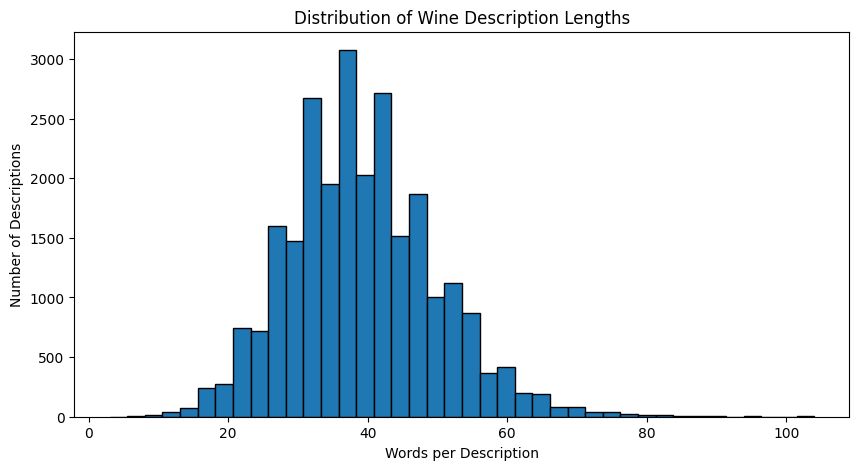

count    25496.000000
mean        39.148298
std         10.599575
min          3.000000
25%         32.000000
50%         38.000000
75%         45.000000
max        104.000000
Name: word_count, dtype: float64


In [ ]:
df_filtered["word_count"] = (
    df_filtered["description"].str.split().str.len()
)

plt.figure(figsize=(10, 5))

plt.hist(df_filtered["word_count"], bins=40, edgecolor="black")

plt.xlabel("Words per Description")
plt.ylabel("Number of Descriptions")
plt.title("Distribution of Wine Description Lengths")

plt.show()

print(df_filtered["word_count"].describe())


In [ ]:
length_summary = (
    df_filtered
    .groupby("style_group")["word_count"]
    .agg(["count", "mean", "median", "std"])
    .sort_values("count", ascending=False)
)

display(length_summary.head(20))


,count,mean,median,std
style_group,,,,
Chardonnay,11760,38.350850,38.0,10.891468
Sparkling,4559,39.416977,38.0,10.039898
Sangiovese,3501,40.479006,40.0,9.515337
White Blend,2443,39.933279,39.0,10.679113
Aromatic White,2352,39.036565,38.0,11.022248
Fortified/Dessert,881,41.236095,40.0,11.162482


The number of words to describe a wine seems pretty even across all 6 wine groups.

Now we explore the most common English word to describle the flavor of wine.

In [ ]:
vectorizer = CountVectorizer(
    stop_words="english",
    max_features=1000,
    min_df=3
)

X_counts = vectorizer.fit_transform(
    df_filtered["description"]
)

words = vectorizer.get_feature_names_out()

frequencies = np.asarray(
    X_counts.sum(axis=0)
).ravel()

word_freq = pd.DataFrame({
    "word": words,
    "count": frequencies
}).sort_values("count", ascending=False)

display(word_freq.head(20))


,word,count
978,wine,15423
352,flavors,11753
383,fruit,8962
26,acidity,8619
56,aromas,7887
634,palate,7804
49,apple,6635
344,finish,6259
744,ripe,5437
275,drink,5033


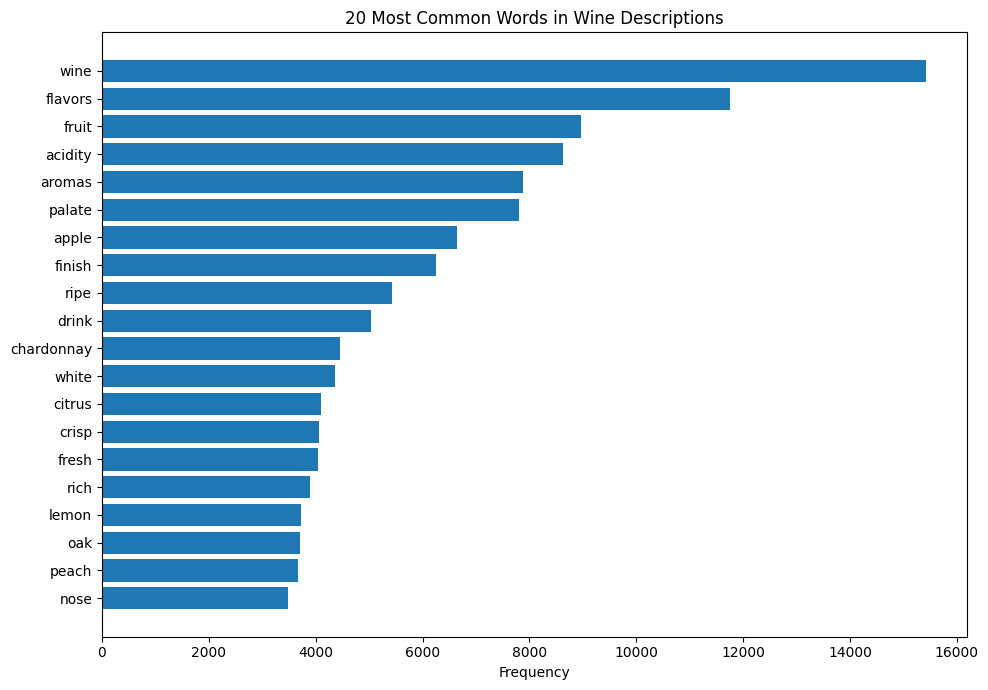

In [ ]:
top_words = word_freq.head(20).sort_values("count")

plt.figure(figsize=(10, 7))

plt.barh(top_words["word"], top_words["count"])

plt.xlabel("Frequency")
plt.title("20 Most Common Words in Wine Descriptions")

plt.tight_layout()
plt.show()


Now we do the same with two word combos

In [ ]:
bigram_vectorizer = CountVectorizer(
    stop_words="english",
    ngram_range=(2, 2),
    min_df=3,
    max_features=1000
)

X_bigrams = bigram_vectorizer.fit_transform(
    df_filtered["description"]
)

bigram_freq = pd.DataFrame({
    "bigram": bigram_vectorizer.get_feature_names_out(),
    "count": np.asarray(
        X_bigrams.sum(axis=0)
    ).ravel()
}).sort_values("count", ascending=False)

display(bigram_freq.head(20))


,bigram,count
437,fruit flavors,1288
662,palate offers,1096
475,green apple,1016
732,ready drink,988
899,tropical fruit,955
836,stone fruit,875
182,buttered toast,791
145,black cherry,776
269,crisp acidity,715
929,white peach,704


Now we explore what word is associated with what wine to see what words tends to describe what wine

In [ ]:
vectorizer = CountVectorizer(
    stop_words="english",
    binary=True,
    min_df=5,
    max_df=0.95
)

X = vectorizer.fit_transform(df_filtered["description"])

terms = vectorizer.get_feature_names_out()

overall_rate = np.asarray(X.mean(axis=0)).ravel()

top_varieties = variety_counts.head(10).index

results = []

for variety in top_varieties:

    mask = (df_filtered["variety"] == variety).to_numpy()

    variety_rate = np.asarray(
        X[mask].mean(axis=0)
    ).ravel()

    lift = variety_rate / (overall_rate + 1e-10)

    valid = variety_rate >= 0.10

    top_indices = np.argsort(
        np.where(valid, lift, -np.inf)
    )[-10:][::-1]

    for idx in top_indices:
        if not valid[idx]:
            continue

        results.append({
            "variety": variety,
            "word": terms[idx],
            "variety_frequency": variety_rate[idx],
            "lift": lift[idx]
        })

distinctive_words = pd.DataFrame(results)

display(distinctive_words)


,variety,word,variety_frequency,lift
0,Chardonnay,pineapple,0.135200,1.780500
1,Chardonnay,oak,0.227346,1.705833
2,Chardonnay,chardonnay,0.273547,1.604407
3,Chardonnay,toast,0.145580,1.584167
4,Chardonnay,tropical,0.111121,1.559235
...,...,...,...,...
95,Moscato,honey,0.337989,5.138559
96,Moscato,sweet,0.536313,4.343657
97,Moscato,pair,0.106145,4.282088
98,Moscato,blossom,0.100559,3.981124


##Second EDA